### <font color='#BFD72'> Table of Contents </font> <a class="anchor" id='toc'></a> 

* [1. Data Preparation](#p1)
* [2. Build the 3 Networks](#p2)
* [3. Inspect edges weight](#p3)
* [4. Visualize the networks](#p4)

# Character Co-occurrence Networks — *Os Maias*

This notebook builds and compares three undirected character networks from `mentions_characters(1).csv`.

- **Raw network:** paragraph co-occurrence plus an additional sentence-level bonus.
- **Jaccard network:** paragraph overlap divided by the number of paragraphs containing either character.
- **Cosine network:** paragraph overlap adjusted for the paragraph frequency of both characters.

The `character` column is used as the canonical node identity. The `mention` column preserves the literal expression found in the novel but is not used as the node name.

## Weighting decisions

For the raw network:

$$
W_{ij} = \sum_{p \in P_{ij}} (1 + 2S_{ij}^{(p)})
$$

where \(P_{ij}\) is the number of shared paragraphs and \(S_{ij}\) is the number of shared sentences. Each character is counted at most once per paragraph and once per sentence.

Jaccard and cosine use **paragraph presence**. They are frequency-adjusted alternatives, not transformed versions of the sentence-enhanced raw weight. This distinction should be stated in the project methodology.

## <font color='#BFD72F'>1. Importing the Dataset and Libraries <font><a class="anchor" id="p2_1"></a>
  
[Back to TOC](#toc)

In [12]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [13]:
from character_network import *

import pandas as pd
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt

In [14]:
mentions = pd.read_csv("Data/mentions_characters.csv")

display(mentions.head())

print("Number of mentions:", len(mentions))
print("Number of characters:", mentions["character"].nunique())
print("Number of paragraphs:", mentions["paragraph_id"].nunique())
print("Number of sentences:", mentions[["paragraph_id", "sent_id"]].drop_duplicates().shape[0])

,paragraph_id,sent_id,chapter,start_char,end_char,mention,label,source,character_id,character,method
0,1,3,1,1006,1018,velho Vilaça,DICT,dict,vilaca_pai,Vilaça,dict_alias
1,2,0,1,40,53,Vilaça Júnior,PER,spacy,vilaca_junior,Vilaça Júnior,alias
2,2,1,1,611,617,Vilaça,PER,spacy,vilaca_pai,Vilaça,context_rule
3,3,1,1,37,43,Vilaça,PER,spacy,vilaca_pai,Vilaça,context_rule
4,4,0,1,156,170,Afonso da Maia,PER,spacy,afonso_maia,Afonso da Maia,alias


Number of mentions: 7207
Number of characters: 103
Number of paragraphs: 3604
Number of sentences: 5686


In [15]:
mentions = mentions.dropna(subset=["character"]).copy()

mentions["character"] = mentions["character"].astype(str).str.strip()

mentions = mentions[mentions["character"] != ""]

# Remove exact duplicate mention records, if any
mentions = mentions.drop_duplicates(
    subset=["paragraph_id", "sent_id", "start_char", "end_char", "character"])

## <font color='#BFD72F'> 2. Build the 3 Networks </font> <a class="anchor" id="p2"></a>
  

[Back to TOC](#toc)

The function returns three graphs, a node table and an edge table. The same node set is used in all graphs. A pair is connected when the two canonical characters occur in at least one shared paragraph.

In [16]:

PARAGRAPH_BONUS = 1
SENTENCE_BONUS = 2

G_raw, G_jaccard, G_cosine, nodes_df, edges_df = build_networks(
    mentions,
    paragraph_bonus=PARAGRAPH_BONUS,
    sentence_bonus=SENTENCE_BONUS,
)

print("Raw network:", G_raw.number_of_nodes(), "nodes,", G_raw.number_of_edges(), "edges")
print("Jaccard network:", G_jaccard.number_of_nodes(), "nodes,", G_jaccard.number_of_edges(), "edges")
print("Cosine network:", G_cosine.number_of_nodes(), "nodes,", G_cosine.number_of_edges(), "edges")

display(nodes_df.sort_values("paragraph_frequency", ascending=False).head(20))

ground_truth_nodes = pd.read_csv("Data/os_maias_ground_truth_nodes.csv", dtype=str)
name_to_id = dict(
    zip(
        ground_truth_nodes["name"].str.strip(),
        ground_truth_nodes["id"].str.strip(),
    )
)

missing_characters = sorted(set(G_raw.nodes) - set(name_to_id))
if missing_characters:
    raise ValueError(
        f"Characters missing from ground-truth node IDs: {missing_characters}"
    )

raw_edges = pd.DataFrame(
    [
        {
            "source": name_to_id[character_1],
            "target": name_to_id[character_2],
            "weight": int(attributes["weight"]),
        }
        for character_1, character_2, attributes in G_raw.edges(data=True)
    ],
    columns=["source", "target", "weight"],
).sort_values(["source", "target"])

raw_edges.to_csv("Data/os_maias_cooccurrence_edges.csv", index=False)
print(f"Updated raw co-occurrence edges: {len(raw_edges)}")


Raw network: 103 nodes, 663 edges
Jaccard network: 103 nodes, 663 edges
Cosine network: 103 nodes, 663 edges


,character,total_mentions,paragraph_frequency,sentence_frequency,chapter_count
10,Carlos da Maia,1902,1564,1866,18
46,João da Ega,1138,962,1124,15
34,Dâmaso Salcede,426,335,413,14
1,Afonso da Maia,323,288,320,17
56,Maria Eduarda,324,278,321,9
19,Craft,239,202,237,13
91,Tomás de Alencar,212,178,207,13
20,Cruges,173,150,166,14
96,Vilaça Júnior,165,146,164,13
95,Vilaça,136,122,135,3


Updated raw co-occurrence edges: 663


## <font color='#BFD72F'>3. Inspect edges weight <font><a class="anchor" id="p3"></a>
  
[Back to TOC](#toc)

- `raw_weight = shared_paragraphs + 2 × shared_sentences`
- `jaccard_weight = shared_paragraphs / (paragraph_frequency_1 + paragraph_frequency_2 - shared_paragraphs)`
- `cosine_weight = shared_paragraphs / sqrt(paragraph_frequency_1 × paragraph_frequency_2)`

The similarity scores are between 0 and 1. A high score means high overlap relative to the characters' paragraph frequencies; it does not mean a high absolute number of shared paragraphs.

In [17]:

display(
    edges_df.sort_values("raw_weight", ascending=False).head(20)[
        ["character_1", "character_2", "raw_weight",
         "shared_paragraphs", "shared_sentences"]
    ]
)

display(
    edges_df.sort_values("jaccard_weight", ascending=False).head(20)[
        ["character_1", "character_2", "jaccard_weight",
         "shared_paragraphs"]
    ]
)

display(
    edges_df.sort_values("cosine_weight", ascending=False).head(20)[
        ["character_1", "character_2", "cosine_weight",
         "shared_paragraphs"]
    ]
)


,character_1,character_2,raw_weight,shared_paragraphs,shared_sentences
133,Carlos da Maia,João da Ega,693,337,178
122,Carlos da Maia,Dâmaso Salcede,294,134,80
141,Carlos da Maia,Maria Eduarda,282,142,70
113,Carlos da Maia,Craft,177,83,47
480,João da Ega,Maria Eduarda,122,68,27
451,Jacob Cohen,Raquel Cohen,116,42,37
12,Afonso da Maia,Carlos da Maia,116,82,17
114,Carlos da Maia,Cruges,111,61,25
447,Jacob Cohen,João da Ega,106,52,27
385,Dâmaso Salcede,João da Ega,105,57,24


,character_1,character_2,jaccard_weight,shared_paragraphs
463,Joaninha Vilar,Viscondessa de Alvim,0.428571,3
527,Madame de l'Estorade,l'Estorade,0.333333,1
451,Jacob Cohen,Raquel Cohen,0.308824,42
311,D. Diogo Coutinho,Sequeira,0.265306,13
560,Maria Eduarda Runa,Padre Vasques,0.222222,2
642,Tancredo,l'Estorade,0.200000,1
320,D. Eugénia Silveira,Teresinha Silveira,0.200000,2
565,Maria Monforte,Pedro da Maia,0.196532,34
301,D. Ana Silveira,Teresinha Silveira,0.187500,3
428,Gertrudes,Trigueiros,0.166667,2


,character_1,character_2,cosine_weight,shared_paragraphs
463,Joaninha Vilar,Viscondessa de Alvim,0.654654,3
527,Madame de l'Estorade,l'Estorade,0.577350,1
451,Jacob Cohen,Raquel Cohen,0.487024,42
642,Tancredo,l'Estorade,0.447214,1
311,D. Diogo Coutinho,Sequeira,0.419573,13
75,Azevedo,Savedra,0.408248,1
560,Maria Eduarda Runa,Padre Vasques,0.365148,2
301,D. Ana Silveira,Teresinha Silveira,0.358569,3
320,D. Eugénia Silveira,Teresinha Silveira,0.338062,2
565,Maria Monforte,Pedro da Maia,0.333301,34


In [18]:

summary_df = pd.DataFrame([
    network_summary(G_raw, "Raw"),
    network_summary(G_jaccard, "Jaccard"),
    network_summary(G_cosine, "Cosine"),
])

display(summary_df)


,network,nodes,edges,density,connected_components,average_degree,average_strength
0,Raw,103,663,0.126214,1,12.873786,145.223301
1,Jaccard,103,663,0.126214,1,12.873786,0.328406
2,Cosine,103,663,0.126214,1,12.873786,0.869448


In [19]:

comparison_df = centrality_comparison(G_raw, G_jaccard, G_cosine)

display(comparison_df.head(25))


,character,raw_strength,raw_rank,jaccard_strength,jaccard_rank,cosine_strength,cosine_rank
0,Carlos da Maia,3079.0,1.0,0.920700,1.0,4.255652,1.0
1,João da Ega,2012.0,2.0,0.853785,4.0,3.051445,2.0
2,Dâmaso Salcede,803.0,3.0,0.614419,18.0,1.719636,11.0
3,Maria Eduarda,741.0,4.0,0.713378,8.0,1.995189,7.0
4,Afonso da Maia,711.0,5.0,0.871901,3.0,2.996483,3.0
5,Craft,572.0,6.0,0.638063,16.0,1.642188,12.0
6,Tomás de Alencar,407.0,7.0,0.589011,22.0,1.826752,9.0
7,Jacob Cohen,394.0,8.0,0.680851,12.0,1.467412,17.0
8,Cruges,381.0,9.0,0.541007,26.0,1.345463,22.0
9,Vilaça Júnior,357.0,10.0,0.528261,28.0,1.384262,21.0


### Spearman correlation between rankings
A high correlation indicates that the character rankings are similar under the different edge-weight definitions.

In [20]:

rank_columns = ["raw_rank", "jaccard_rank", "cosine_rank"]
rank_correlations = comparison_df[rank_columns].corr(method="spearman")
display(rank_correlations)


,raw_rank,jaccard_rank,cosine_rank
raw_rank,1.000000,0.795482,0.820465
jaccard_rank,0.795482,1.000000,0.986337
cosine_rank,0.820465,0.986337,1.000000


<font color='#BFD72F' size=6> 4. Vizualise the networks </font> <a class="anchor" id="p4"></a>
  
[Back to TOC](#toc)


A force-directed layout positions strongly connected nodes closer together. For a fair visual comparison, calculate the layout once from the raw graph and reuse those coordinates for all three plots. Node size below represents weighted degree within each displayed graph; edge thickness represents edge weight within that graph.

For the full graphs, labels may overlap. The top-edge plots later in the notebook are often easier to read.


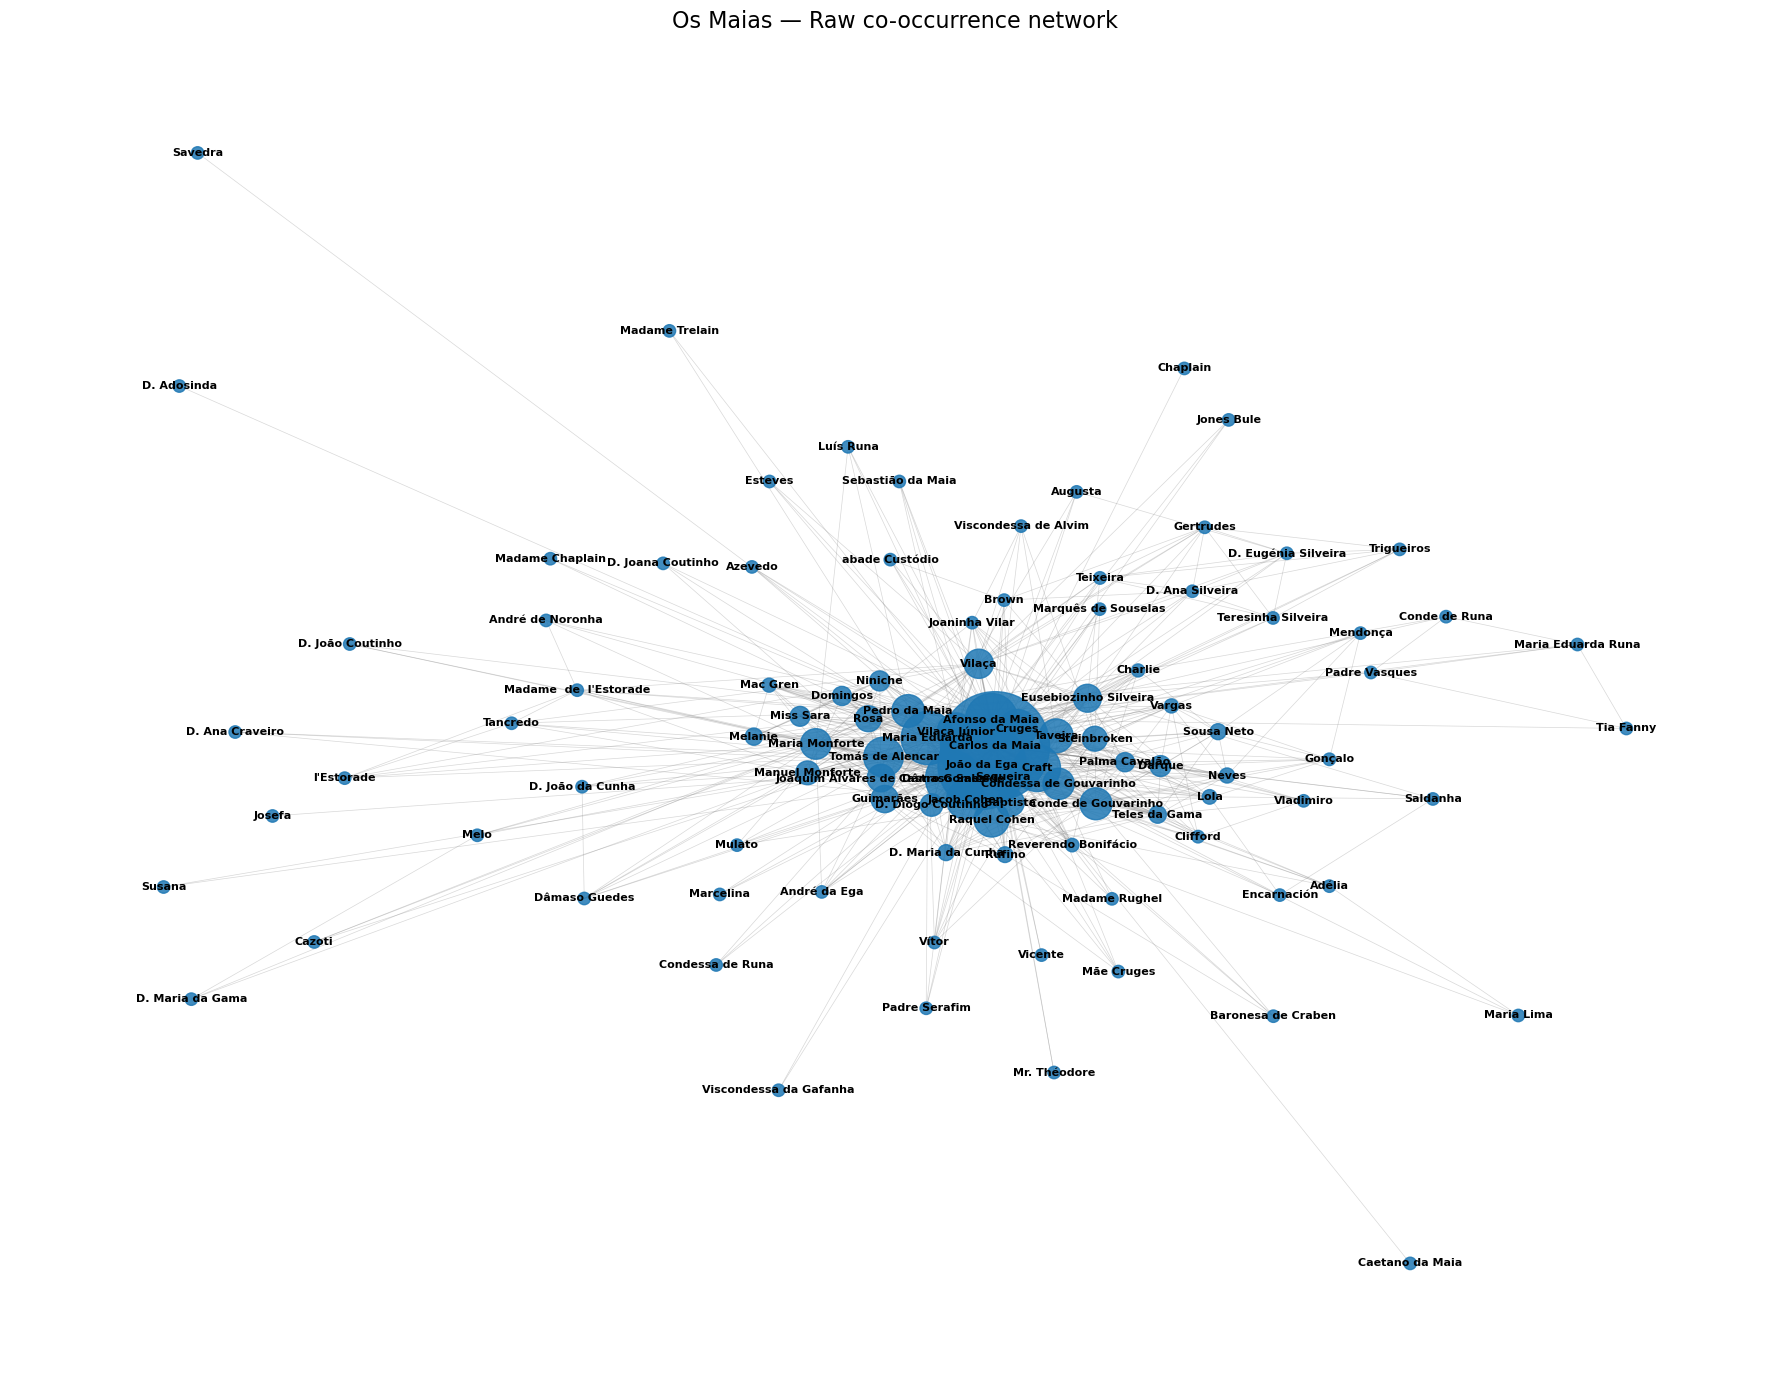

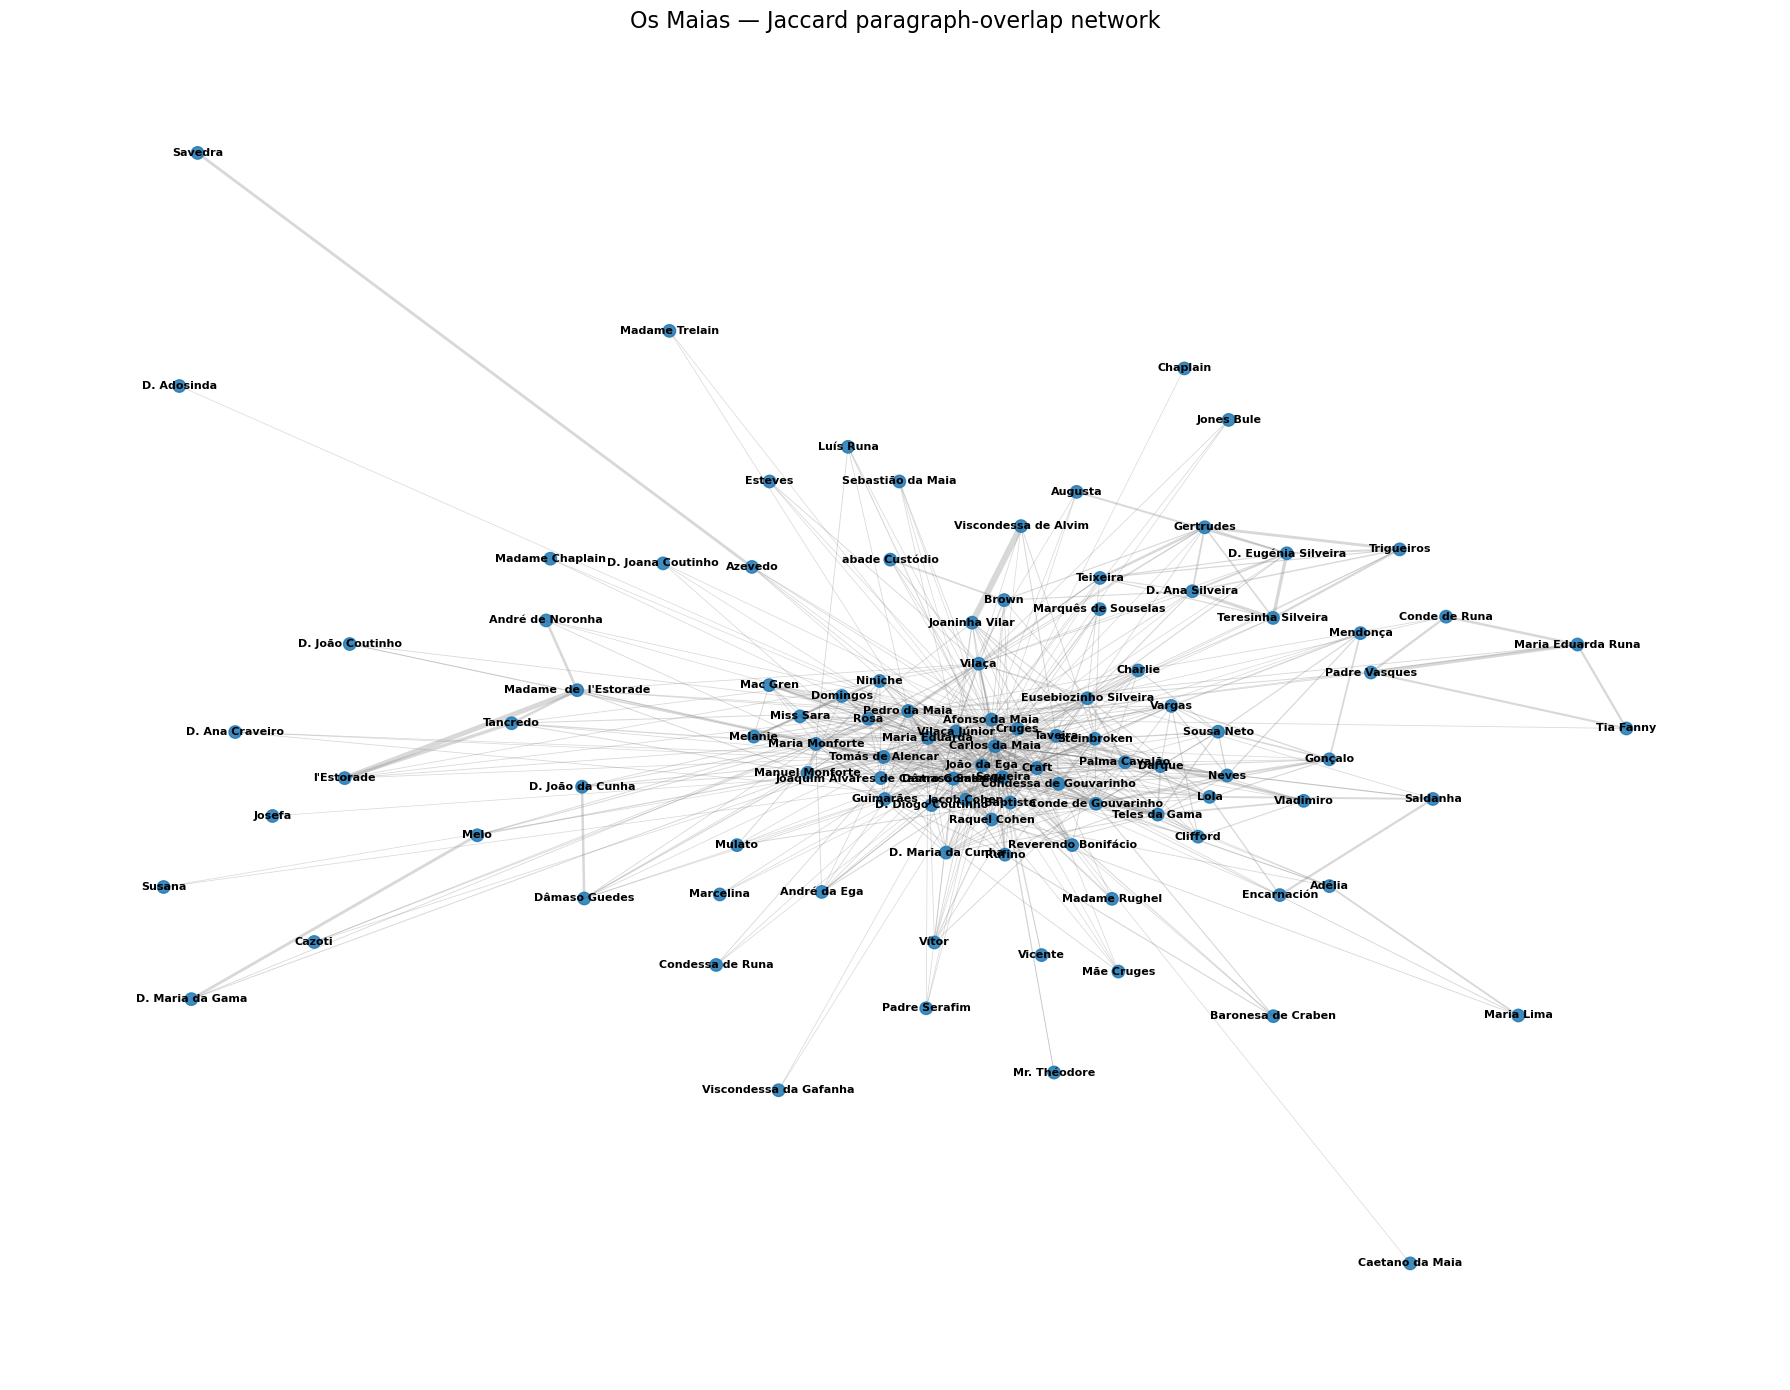

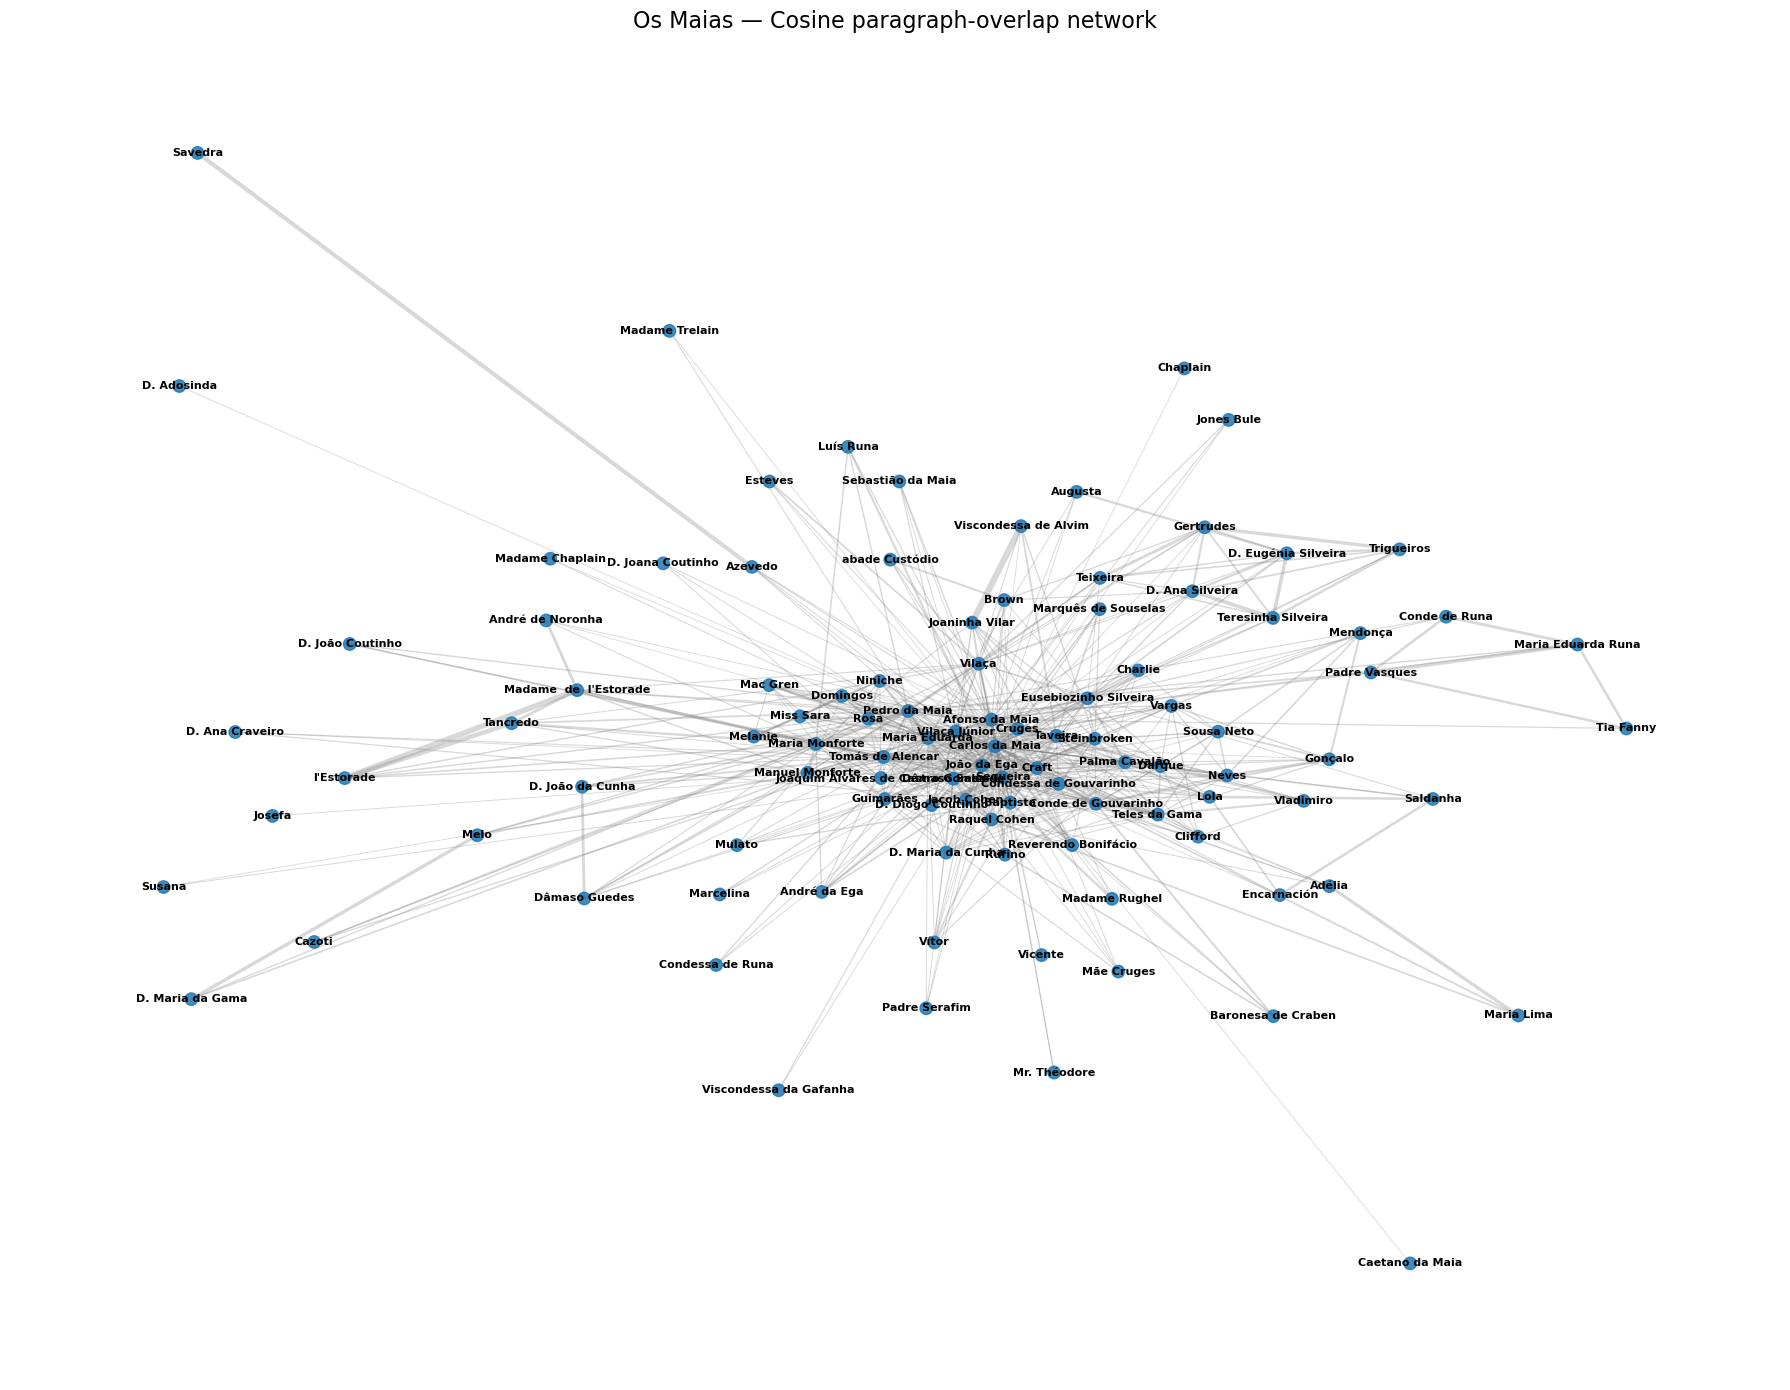

In [21]:

common_pos = nx.spring_layout(
    G_raw,
    weight="weight",
    seed=42,
    k=0.8,
    iterations=100,
)

fig, ax = plot_network(
    G_raw,
    "Os Maias — Raw co-occurrence network",
    pos=common_pos,
)
plt.show()

fig, ax = plot_network(
    G_jaccard,
    "Os Maias — Jaccard paragraph-overlap network",
    pos=common_pos,
)
plt.show()

fig, ax = plot_network(
    G_cosine,
    "Os Maias — Cosine paragraph-overlap network",
    pos=common_pos,
)
plt.show()


In [22]:
G_raw